# Zachary Weed

# [Problem 1] - Conda Virtual Environment

### Installation of PyTorch and Jupyter

In [2]:
!pip install torch jupyter

import torch
import math
import numpy as np
import random
import torch.optim as optimizers
from matplotlib import pyplot as plt
from torch.utils.data import TensorDataset
from torch.utils.data import DataLoader

### MPS on Macbook Device

In [39]:
# MPS (Metal Performance Shaders) identified in lieue of CUDA
mps = torch.backends.mps.is_available()
mps_built = torch.backends.mps.is_built()

print("MPS built:", mps_built)
print("MPS Available:", mps)

device = torch.device("mps" if mps else "cpu")
print("Selected device:", device)

MPS built: True
MPS Available: True
Selected device: mps


# [Problem 2] - Calculate Gradients of Function with Calculus and Autograd

### Defining A Loss Function

In [5]:
def loss(x, y):
    return ((x)/(y+x**2)) + math.e ** (-y * x)

### Defining A Function for Determining Gradients with Autograd

In [7]:
def auto_gradients(x, y):
    # Defining these Floats within Tensors for Autograd
    params = torch.tensor([x, y], requires_grad = True)
    # Call function with Tensors
    l = loss(*params)
    # Backpropagates gradients through function call graph
    l.backward()
    # Compute gradient of both x & y
    return params.grad

### Autogradients (x, y) = (0, 1)

In [8]:
# computes autogradients
print(f" Gradient of x & y: {auto_gradients(0.0, 1.0)}")

 Gradient of x & y: tensor([0., -0.])


### Autogradients (x, y) = (1, 0)

In [36]:
# Notes: because it results in a Divide by 0, the function is technically undefined
# Thus, this works with different values: https://edstem.org/us/courses/94615/discussion/7596048?comment=17665967
print(f" Gradient of x & y: {auto_gradients(1.0, 0.0)}")

 Gradient of x & y: tensor([-1., -2.])


### Defining A Function for Determining Gradients with Autograd

In [11]:
def manual_gradients(x, y, nudge = 1e-6):
    # nudge x
    derivative_wrt_x = (
        loss( x + nudge, y ) - loss( x, y )
    ) / nudge
    # nudge y
    derivative_wrt_y = (
        loss( x, nudge + y ) - loss( x, y )
    ) / nudge
    return [ derivative_wrt_x, derivative_wrt_y]

### Manual gradients (x, y) = (0, 1)

In [12]:
auto_gradients_a = auto_gradients(0.0, 1.0)
manual_gradients_a = manual_gradients(0.0, 1.0)

print(f" Manual Gradient of x: {manual_gradients_a[0]}")
print(f" Manual Gradient of y: {manual_gradients_a[1]}\n")

# Difference is negligible 0 in this context
print(f" Difference of x from Autogradient: {manual_gradients_a[0] - auto_gradients_a[0]}")
print(f" Difference of y from Autogradient: {manual_gradients_a[1] - auto_gradients_a[1]}")

 Manual Gradient of x: 5.000444502911705e-07
 Manual Gradient of y: 0.0

 Difference of x from Autogradient: 5.000444502911705e-07
 Difference of y from Autogradient: 0.0


### Manual Gradients (x, y) = (1, 0)

In [38]:
# Chose Different Values because of Division by 0 error
# https://edstem.org/us/courses/94615/discussion/7596048?comment=17665967
auto_gradients_b = auto_gradients(1.0, 0.0)
manual_gradients_b = manual_gradients(1.0, 0.0)

print(f" Manual Gradient of x: {manual_gradients_b[0]}")
print(f" Manual Gradient of y: {manual_gradients_b[1]}\n")

print(f" Difference of x from Autogradient: {manual_gradients_b[0] - auto_gradients_b[0]}")
print(f" Difference of y from Autogradient: {manual_gradients_b[1] - auto_gradients_b[1]}")

 Manual Gradient of x: -0.9999990000508774
 Manual Gradient of y: -1.9999984999241605

 Difference of x from Autogradient: 1.0132789611816406e-06
 Difference of y from Autogradient: 1.5497207641601562e-06


# [Problem 3] - Training Data Loaders

### Code for Building Labels & Features

In [34]:
# Celsius
def generate_celsius_data_points(range_low, range_high, n = 100):
    return [random.randint( range_low, range_high ) for _ in range(n)]

# Given our Celsius data, we can compute Fahrenheit versions as well
def generate_fahrenheit_data_points(celsius):
    fahrenheit = []
    for x in celsius:
        fahrenheit.append((x * 1.8) + 32)
    return torch.tensor(fahrenheit)

# Builds tensors of both sets of data
torch_celsius = torch.tensor(generate_celsius_data_points(-20, 45))
torch_fahrenheit = generate_fahrenheit_data_points(torch_celsius)

### Plot Data

Text(0, 0.5, 'celsius')

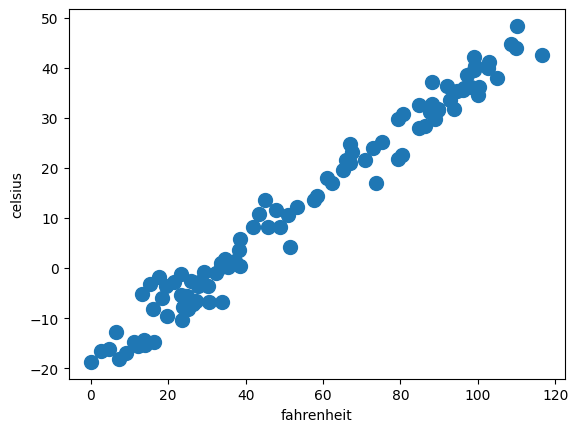

In [33]:
# Plots data for visualization purposes
plt.plot(torch_fahrenheit, torch_celsius, 'o', markersize = 10)
plt.xlabel('fahrenheit')
plt.ylabel('celsius')

### Building Model, Loss, and Noise Functions

In [32]:
# Defines a traditional model
def model(tensor, w, b):
    return w * tensor + b

# Defines a loss function with Mean Square Error
def loss_function(tensor_a, tensor_b):
    squared_differences = ( tensor_a - tensor_b ) ** 2
    return squared_differences.mean()

# Applies Gaussian Noise with σ of 3
def apply_noise(tensor):
    return tensor + torch.randn_like(tensor) * 3

### Apply Gaussian Noise on Datasets

In [17]:
# Applies Gaussian noise with σ = 3
torch_fahrenheit = apply_noise(torch_fahrenheit.float())
torch_celsius = apply_noise(torch_celsius.float())

### Shuffles & Performs a Train Test Split

In [26]:
batch_size = 10

dataset = TensorDataset(torch_celsius, torch_fahrenheit)

# Computes numbers used for performing split of data
number_of_samples = len(dataset)
len_of_train = int( 0.7 * number_of_samples )
len_of_validation = number_of_samples - len_of_train

# Performs a split of the data
train_dataset, validation_dataset = torch.utils.data.random_split(
    dataset, [len_of_train, len_of_validation]
)

# Loads training dataset into a DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size = batch_size,
    shuffle = True
)

# Loads validation dataset into a DataLoader
validation_loader = DataLoader(
    validation_dataset,
    batch_size = batch_size,
    shuffle = False
)

### Defines a Training Loop

In [28]:
def training_loop(number_of_epochs, optimizer, params, training_loader, validation_loader):
    for epoch in range(1, number_of_epochs + 1):
        training_loss = 0.0

        # We split data in DataLoader back into Celsius and Fahrenheit
        for celsius_batch, fahrenheit_batch in train_loader:
            # predicts Fahrenheit from model
            predicted_fahrenheit = model(celsius_batch, *params)
            # applies loss function
            loss = loss_function(predicted_fahrenheit, fahrenheit_batch)

            # clears gradients
            optimizer.zero_grad()
            # backpropagates
            loss.backward()
            # steps optimizer forward
            optimizer.step()

            # re-assigns training loss
            training_loss = loss.item()

        validation_loss = 0.0

        # Performs validation, sans gradient descent
        with torch.no_grad():
            # Given we re-split the data, we then perform predictions
            # While also storing the validation loss between epochs
            for celsius_batch, fahrenheit_batch in validation_loader:
                predicted_fahrenheit = model(celsius_batch, *params)
                loss = loss_function(predicted_fahrenheit, fahrenheit_batch)
                validation_loss = loss.item()

        # Calculates total validation and training loss
        validation_loss /= len(validation_loader)
        training_loss /= len(training_loader)

        if epoch <= 3 or epoch % 500 == 0:
            print(f"Epoch {epoch}, Training loss {training_loss:.4f},"
                  f" Validation loss {validation_loss:.4f}")

    return params

### Defines Optimizers With Learning Rate

In [29]:
# Defines an Adam optimizer that include an ability for storing Gradient
params = torch.tensor([1.0, 0.0], requires_grad = True)
optimizer = optimizers.Adam([params], lr = 1e-2)

### Calls Training Loop

In [30]:
# Training loop is called here, storing results in params
params = training_loop(number_of_epochs = 3000, optimizer = optimizer, params = params, training_loader = train_loader, validation_loader = validation_loader)

Epoch 1, Training loss 290.4192, Validation loss 598.7736
Epoch 2, Training loss 188.8295, Validation loss 566.9892
Epoch 3, Training loss 266.7124, Validation loss 538.8440
Epoch 500, Training loss 11.4864, Validation loss 16.8241
Epoch 1000, Training loss 3.0733, Validation loss 4.3904
Epoch 1500, Training loss 2.8494, Validation loss 4.3636
Epoch 2000, Training loss 3.2359, Validation loss 4.3842
Epoch 2500, Training loss 7.5640, Validation loss 4.3839
Epoch 3000, Training loss 2.4060, Validation loss 4.3302


### Plots Data

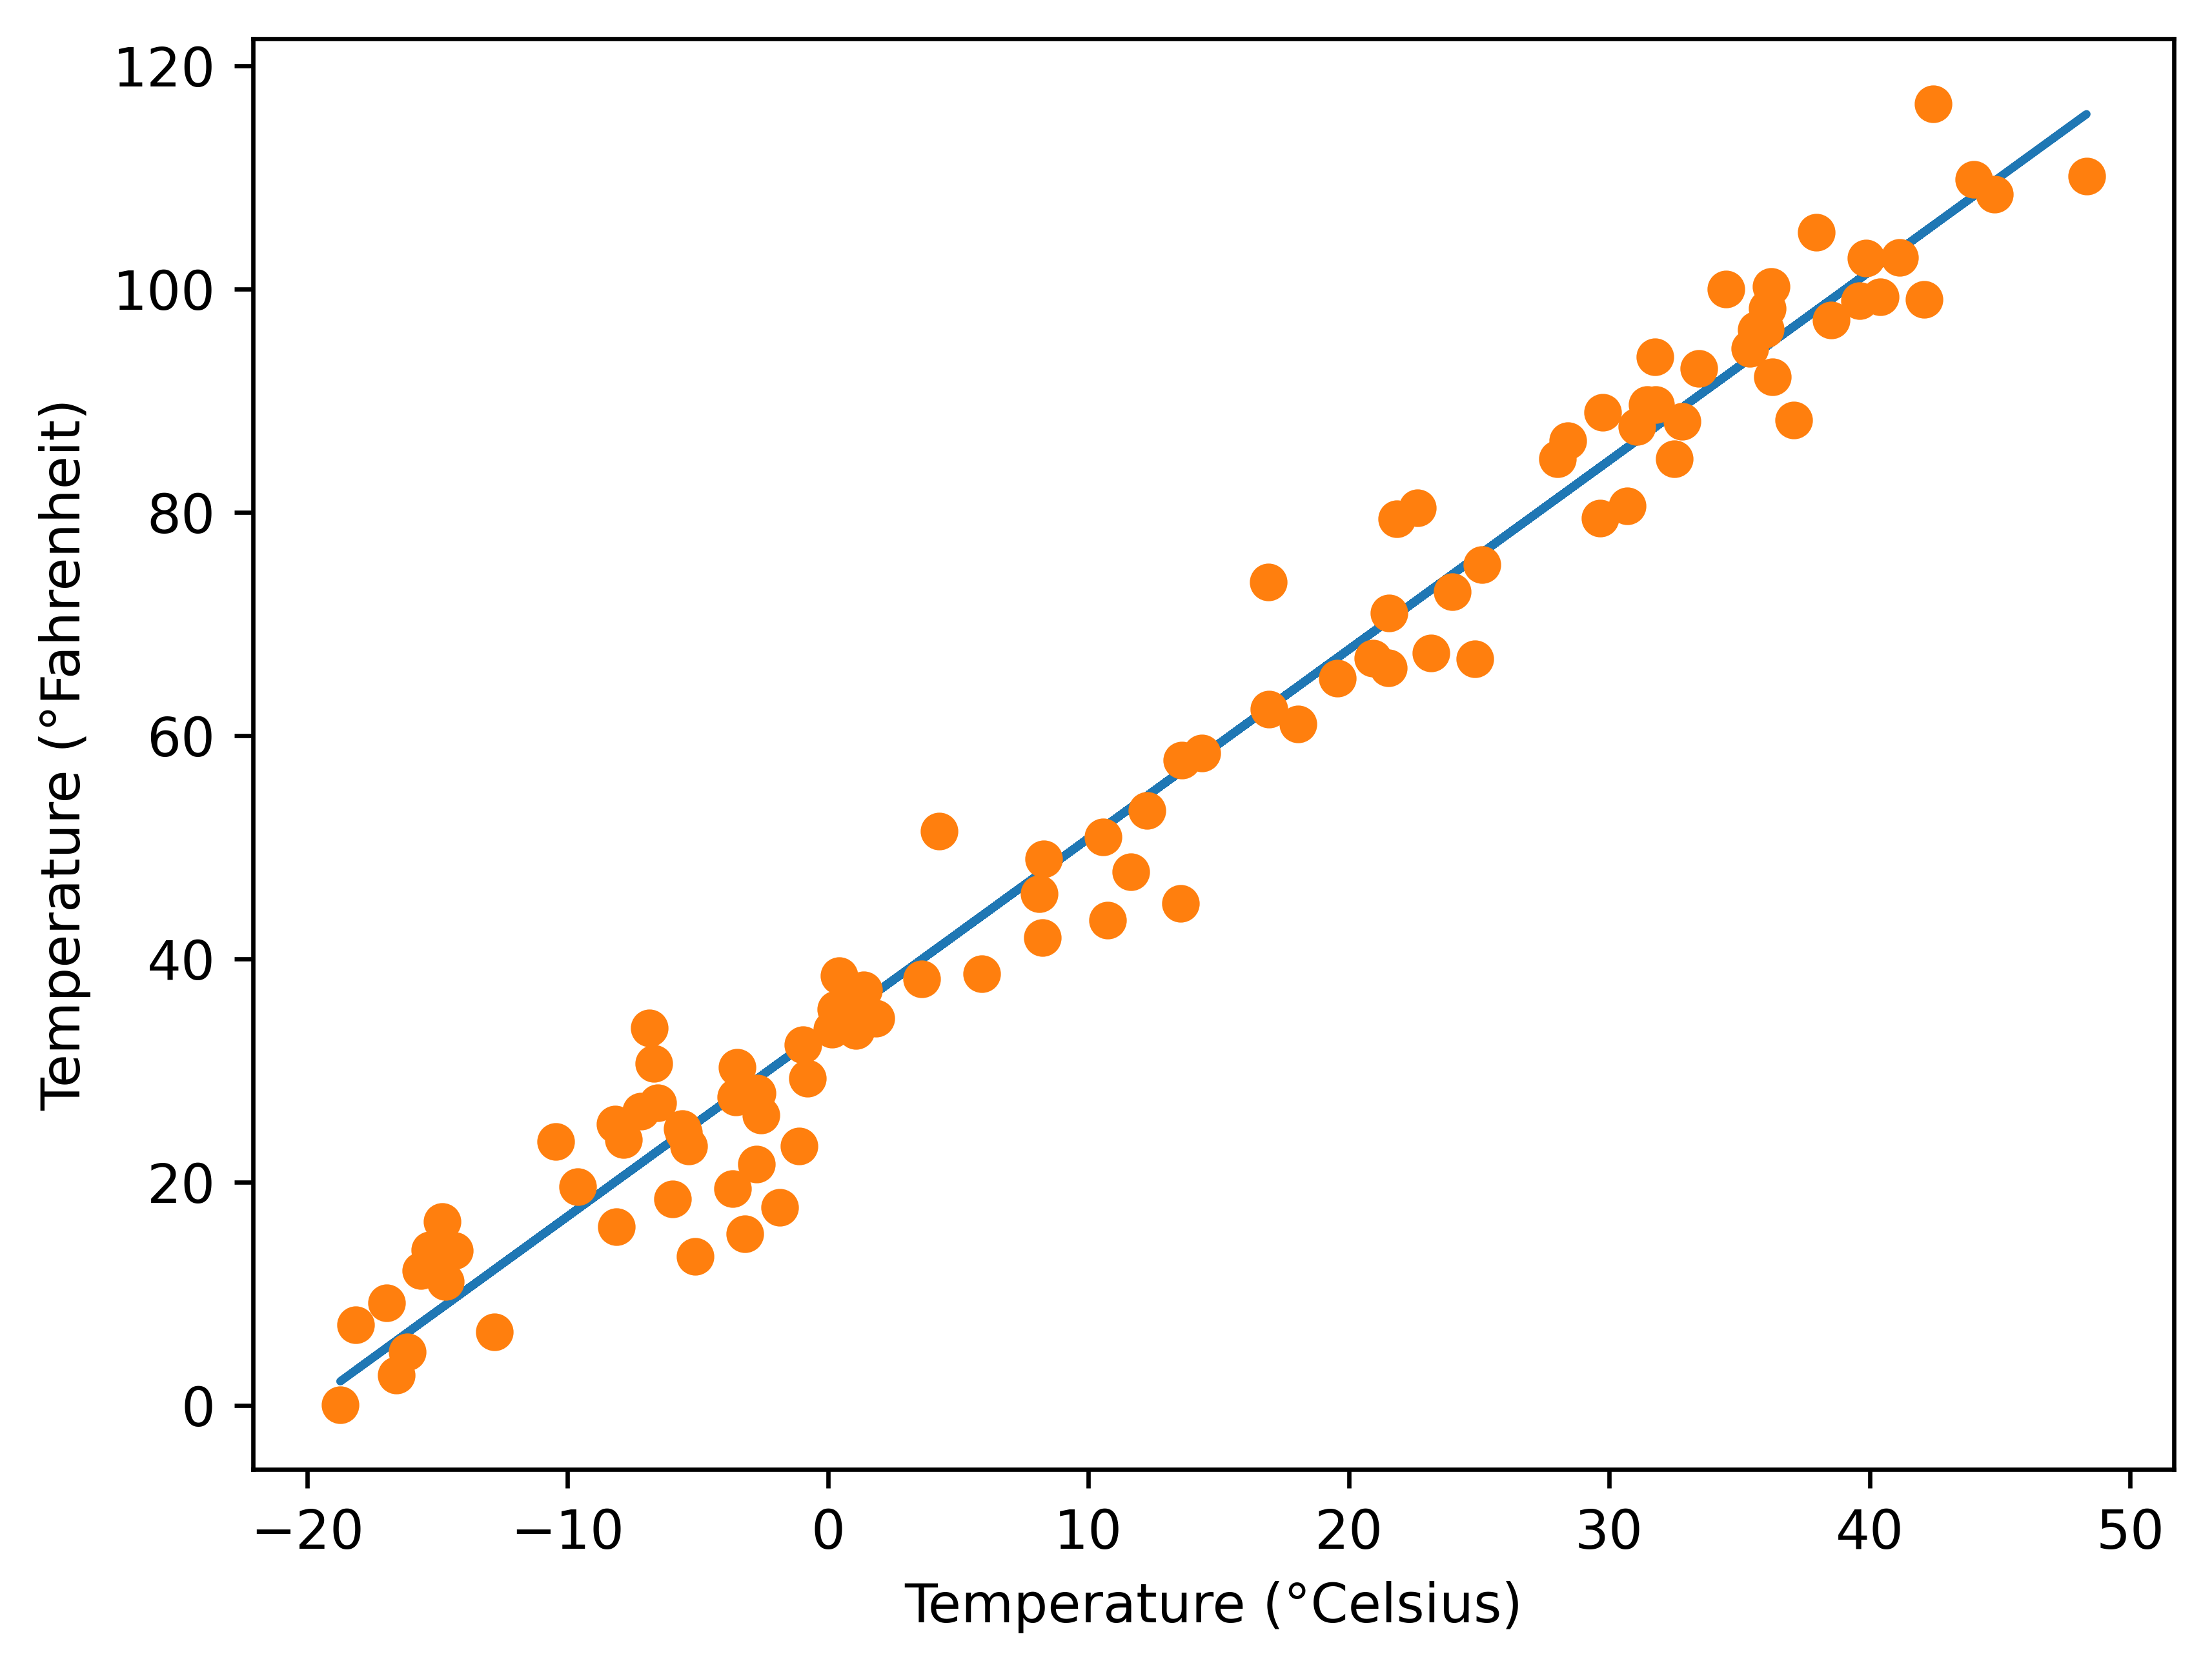

In [31]:
# Calls model with the params
t_p = model(torch_celsius, *params)

# Performs actual plotting
figure = plt.figure(dpi = 600)

plt.xlabel("Temperature (°Celsius)")
plt.ylabel("Temperature (°Fahrenheit)")

plt.plot(torch_celsius.numpy(), t_p.detach().numpy())
plt.plot(torch_celsius.numpy(), torch_fahrenheit.numpy(), 'o')